# EDA do WANDS

O que olhar antes de modelar: qualidade dos dados, distribuição dos rótulos, o que as buscas pedem e quais sinais separam um produto Exact de um Irrelevant.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from product_search import config
from product_search.data.loading import load_labels, load_products
from product_search.text import tokenize

sns.set_theme(style="whitegrid", context="notebook")
ORDER = ["Exact", "Partial", "Irrelevant"]
PALETTE = {"Exact": "#2a9d8f", "Partial": "#e9c46a", "Irrelevant": "#adb5bd"}


def read(name):
    return pd.read_csv(config.DATA_DIR / name, sep="\t")


raw_products, queries, raw_labels = read("product.csv"), read("query.csv"), read("label.csv")
products, labels = load_products(), load_labels()
print(f"{len(raw_products):,} produtos | {len(queries)} queries | {len(raw_labels):,} julgamentos")

42,994 produtos | 480 queries | 233,448 julgamentos


## 1. Qualidade dos dados

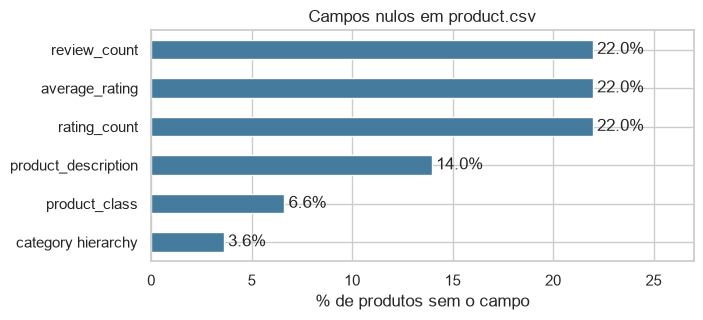

In [2]:
nulls = raw_products.isna().mean().mul(100).sort_values()
ax = nulls[nulls > 0].plot.barh(figsize=(7, 3), color="#457b9d")
ax.set(xlabel="% de produtos sem o campo", title="Campos nulos em product.csv")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlim(0, 27);

In [3]:
numeric = ["rating_count", "average_rating", "review_count"]
missing = raw_products[numeric].isna()
pairs = raw_labels.groupby(["query_id", "product_id"]).label.nunique()

print(f"pares (query, produto) repetidos:      {raw_labels.duplicated(['query_id', 'product_id']).sum():,}")
print(f"pares com rótulos conflitantes:        {(pairs > 1).sum()}")
print(f"produtos sem avaliação:                {missing.all(axis=1).mean():.1%}")
print(f"algum numérico nulo sem os outros:     {(missing.any(axis=1) & ~missing.all(axis=1)).sum()}")
print(f"produtos citados em label.csv:         {raw_labels.product_id.nunique():,} de {len(raw_products):,}")

pares (query, produto) repetidos:      1,575
pares com rótulos conflitantes:        14
produtos sem avaliação:                22.0%
algum numérico nulo sem os outros:     0
produtos citados em label.csv:         42,986 de 42,994


- A descrição falta em 14% dos produtos e a classe em 6,6%. Ficam como texto vazio.
- Os três campos numéricos são nulos juntos, sempre nos mesmos 22%. Não é dado perdido: é produto sem nenhuma avaliação. Por isso ficam como NaN, que o LightGBM trata como um caso à parte. Preencher com 0 diria "nota zero".
- Há 1.575 pares repetidos em `label.csv`. Mantenho um de cada e descarto os 14 com rótulos diferentes, porque não dá para saber qual está certo.

## 2. Rótulos

queries sem nenhum Exact: 101 | sem Exact nem Partial: 1
count     480.0
mean      483.0
std       708.0
min         1.0
25%       122.0
50%       215.0
75%       504.0
max      4329.0


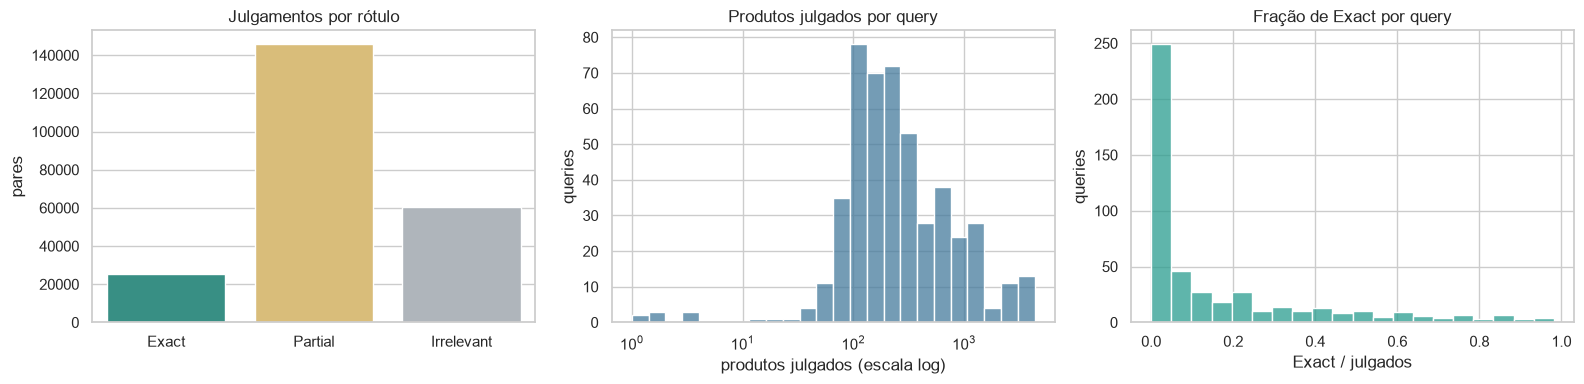

In [4]:
per_query = labels.groupby("query_id").label.value_counts().unstack(fill_value=0).reindex(columns=ORDER, fill_value=0)
per_query["judged"] = per_query[ORDER].sum(axis=1)
per_query["exact_share"] = per_query.Exact / per_query.judged

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(labels, x="label", order=ORDER, hue="label", palette=PALETTE, ax=axes[0])
axes[0].set(title="Julgamentos por rótulo", xlabel="", ylabel="pares")
sns.histplot(per_query.judged, log_scale=True, color="#457b9d", ax=axes[1])
axes[1].set(title="Produtos julgados por query", xlabel="produtos julgados (escala log)", ylabel="queries")
sns.histplot(per_query.exact_share, bins=20, color="#2a9d8f", ax=axes[2])
axes[2].set(title="Fração de Exact por query", xlabel="Exact / julgados", ylabel="queries")
plt.tight_layout()

no_relevant = (per_query[["Exact", "Partial"]].sum(axis=1) == 0).sum()
print(f"queries sem nenhum Exact: {(per_query.Exact == 0).sum()} | sem Exact nem Partial: {no_relevant}")
print(per_query.judged.describe().round(0).to_string())

- Partial domina (63% dos pares) e Exact é só 11%. Uma métrica binária jogaria fora a diferença entre Partial e Irrelevant, então o ranking é avaliado com nDCG graduado (Exact 2, Partial 1, Irrelevant 0).
- 101 queries não têm nenhum Exact. Nelas o recall é indefinido, então ficam fora da média das métricas binárias. Uma query não tem nem Exact nem Partial e sai do dataset.
- O número de julgados vai de 1 a 4.329 por query, e a maioria das queries tem menos de 10% de Exact. Por isso o split é por query e estratificado pela fração de Exact: os três conjuntos ficam com dificuldade parecida.

## 3. Buscas

['certified international melamine', 'tile backsplash', 'small ladies rocker swivel recliner', 'brunk ship wheel', 'queen ann style living room chair', 'bedroom accessories', 'oliver parsons', 'farmhouse hood vent']


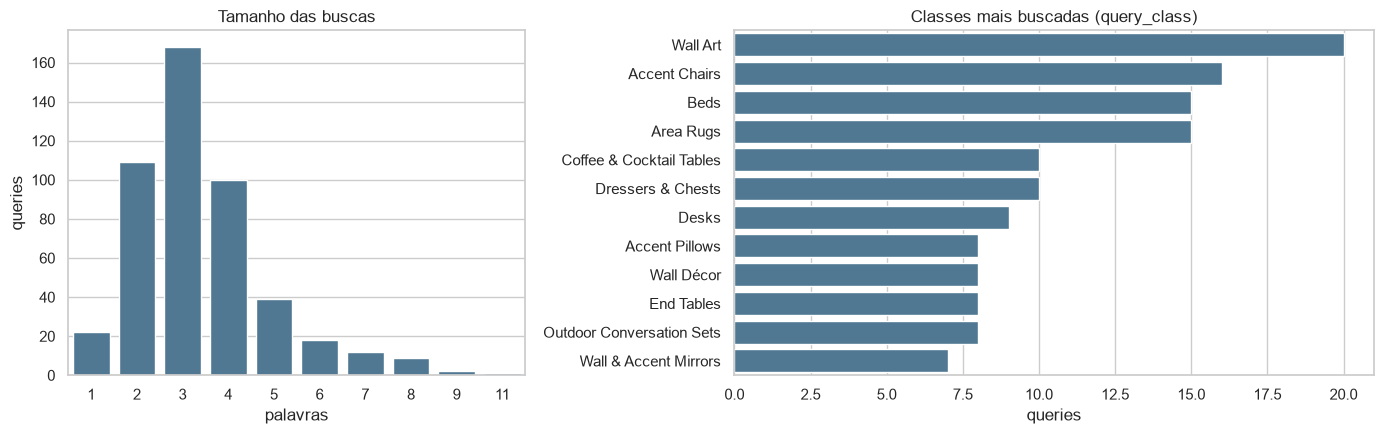

In [5]:
queries["n_tokens"] = queries["query"].map(lambda q: len(tokenize(q)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
sns.countplot(queries, x="n_tokens", color="#457b9d", ax=axes[0])
axes[0].set(title="Tamanho das buscas", xlabel="palavras", ylabel="queries")
top = queries.query_class.value_counts().head(12)
sns.barplot(x=top.values, y=top.index, color="#457b9d", ax=axes[1])
axes[1].set(title="Classes mais buscadas (query_class)", xlabel="queries", ylabel="")
plt.tight_layout()

print(queries.sample(8, random_state=config.SEED)["query"].tolist())

- As buscas são curtas (mediana de 3 palavras), então cada palavra pesa muito.
- Há buscas genéricas ("bedroom accessories") e buscas por marca ou linha ("oliver parsons", "certified international melamine"). Nomes próprios pedem busca lexical (BM25); buscas genéricas e sinônimos pedem embeddings. É o argumento para o retrieval híbrido.

## 4. Produtos: texto e atributos

mediana de atributos por produto: 55
exemplo: capacityquarts:7|producttype : slow cooker|programmablecookingsettings : slow cook|overallheight-toptobottom:14.2|overalldepth-fronttoback:11.3|programmablefoodsettings : soup|overallwidth-sidetoside: ...


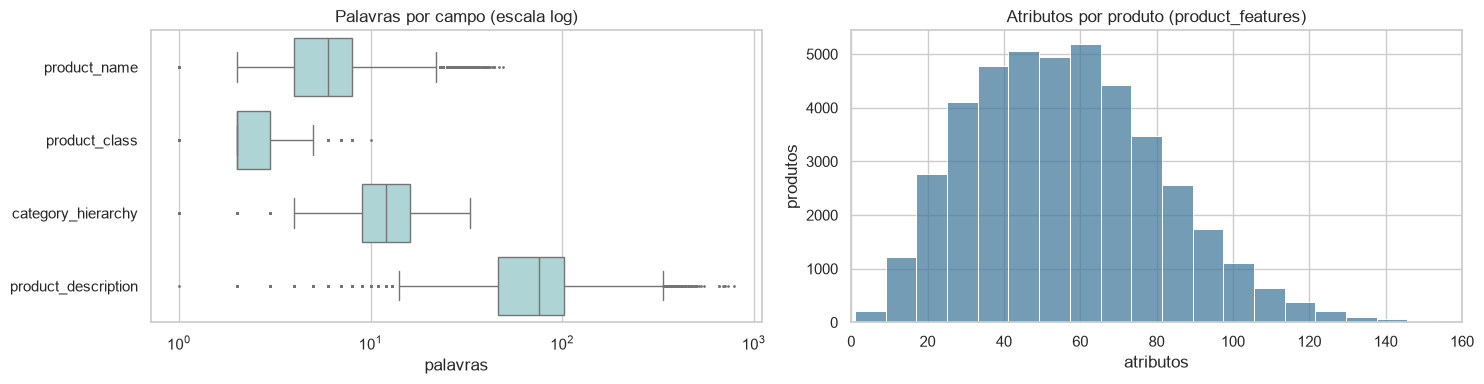

In [6]:
fields = ["product_name", "product_class", "category_hierarchy", "product_description"]
lengths = pd.DataFrame({f: products[f].str.split().str.len() for f in fields}).melt(var_name="campo", value_name="palavras")
n_attributes = products.product_features.str.count(r"\|") + products.product_features.ne("").astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(lengths[lengths.palavras > 0], x="palavras", y="campo", log_scale=True, color="#a8dadc", fliersize=1, ax=axes[0])
axes[0].set(title="Palavras por campo (escala log)", ylabel="")
sns.histplot(n_attributes, bins=50, color="#457b9d", ax=axes[1])
axes[1].set(title="Atributos por produto (product_features)", xlabel="atributos", ylabel="produtos", xlim=(0, 160))
plt.tight_layout()

print(f"mediana de atributos por produto: {n_attributes.median():.0f}")
print("exemplo:", raw_products.product_features[1][:200], "...")

- O nome tem ~6 palavras e a descrição ~75. A descrição dilui o sinal num embedding, então os embeddings usam só nome, classe e categorias. O BM25 usa a descrição também, porque a normalização por tamanho do documento compensa.
- Os produtos têm mediana de 55 atributos (dimensões, cor, material, estilo). É de onde vem o grupo de features `attributes`.

## 5. Campos numéricos

            rating_count  average_rating  review_count
label                                                 
Exact               42.0             4.5          32.0
Partial             54.0             4.5          41.0
Irrelevant          44.0             4.5          33.0


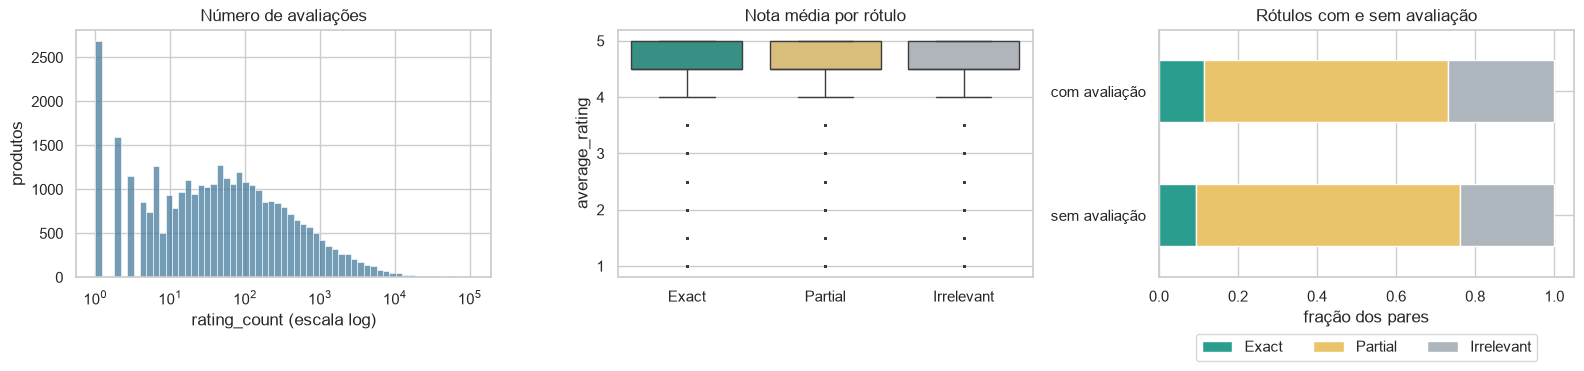

In [7]:
judged = labels.merge(products[["product_id", *numeric]], on="product_id")
judged["has_rating"] = judged.rating_count.notna()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(products.rating_count.dropna(), log_scale=True, color="#457b9d", ax=axes[0])
axes[0].set(title="Número de avaliações", xlabel="rating_count (escala log)", ylabel="produtos")
sns.boxplot(judged, x="label", y="average_rating", order=ORDER, hue="label", palette=PALETTE, fliersize=1, ax=axes[1])
axes[1].set(title="Nota média por rótulo", xlabel="", ylabel="average_rating")
rate = judged.groupby("has_rating").label.value_counts(normalize=True).unstack()[ORDER]
rate.index = ["sem avaliação", "com avaliação"]
rate.plot.barh(stacked=True, color=PALETTE, ax=axes[2], legend=False)
axes[2].set(title="Rótulos com e sem avaliação", xlabel="fração dos pares")
axes[2].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()

print(judged.groupby("label")[numeric].median().reindex(ORDER).round(2).to_string())

- A nota média é praticamente igual nos três rótulos (mediana 4,5). Ter avaliação muda pouco a taxa de Exact (11,5% contra 9,3%).
- Faz sentido: os rótulos medem se o produto atende à busca, não se ele vende bem. Espero pouco ganho do grupo `numeric`. Com rótulos de clique ou compra, isso mudaria.

## 6. Que sinais separam Exact de Irrelevant?

             nome  atributos  mesma_classe
label                                     
Exact       0.616      0.455         0.641
Partial     0.478      0.343         0.460
Irrelevant  0.434      0.258         0.039


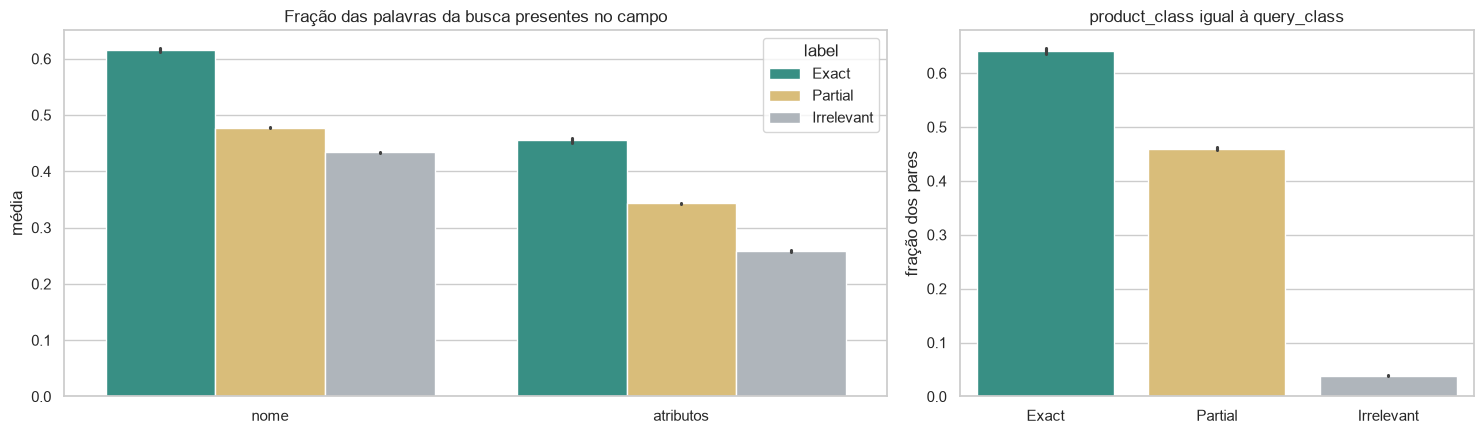

In [8]:
q_tokens = queries.set_index("query_id")["query"].map(lambda q: set(tokenize(q)))
q_class = queries.set_index("query_id").query_class
by_id = products.set_index("product_id")
name_tokens = by_id.product_name.map(lambda t: set(tokenize(t)))
attr_tokens = by_id.attributes.map(lambda t: set(tokenize(t)))


pairs = list(zip(labels.query_id, labels.product_id, strict=True))


def overlap(tokens):
    return [len(q_tokens[q] & tokens[p]) / max(len(q_tokens[q]), 1) for q, p in pairs]


signals = labels.assign(
    nome=overlap(name_tokens),
    atributos=overlap(attr_tokens),
    mesma_classe=[by_id.product_class[p] == q_class[q] for q, p in pairs],
)
long = signals.melt(id_vars="label", value_vars=["nome", "atributos"], var_name="campo", value_name="overlap")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.barplot(long, x="campo", y="overlap", hue="label", hue_order=ORDER, palette=PALETTE, ax=axes[0])
axes[0].set(title="Fração das palavras da busca presentes no campo", xlabel="", ylabel="média")
sns.barplot(signals, x="label", y="mesma_classe", order=ORDER, hue="label", palette=PALETTE, ax=axes[1])
axes[1].set(title="product_class igual à query_class", xlabel="", ylabel="fração dos pares")
plt.tight_layout()

print(signals.groupby("label")[["nome", "atributos", "mesma_classe"]].mean().reindex(ORDER).round(3).to_string())

- Ter as palavras da busca no **nome** separa Exact (62%) do resto (48% e 43%). Nos **atributos** a separação é em degraus (46%, 34% e 26%), o que justifica um grupo de features só para eles.
- A classe do produto bater com a `query_class` é o sinal mais forte de todos (64% nos Exact contra 4% nos Irrelevant). Mas a `query_class` não existe na hora da busca: o usuário só digita o texto. Não entra como feature; um classificador de classe da busca fica como próximo passo.

## Decisões que saem daqui

| Achado | Decisão |
|---|---|
| Pares repetidos e 14 conflitantes | deduplicar e descartar os conflitantes |
| Campos numéricos nulos juntos (22%) | manter NaN |
| Exact raro, Partial dominante | nDCG@10 graduado para ranking; Recall@100 só com Exact para retrieval |
| Dificuldade muito desigual entre queries | split por query, estratificado pela fração de Exact |
| Buscas curtas, com nomes próprios e termos genéricos | retrieval híbrido (BM25 + embeddings) |
| Nome e atributos separam os rótulos | features de overlap por campo e de atributos |
| Nota média não separa os rótulos | grupo `numeric` entra, com expectativa baixa (a ablação confirma) |
| `query_class` é forte, mas não existe em produção | fora das features |